# NSSC 2026 — Unsupervised Anomaly Detection in Mars HiRISE Imagery
## Phase 1.1 — Convolutional Autoencoder: Architecture Design

**Scope of this notebook:** Phase 1.1 only — designing, implementing, and sanity-checking a
Convolutional Autoencoder (CAE) built **from scratch** (no pretrained weights, no transfer
learning, no pretrained backbones), whose bottleneck produces a fixed-length 1D latent vector
for every 227×227 grayscale Mars image. This latent vector is what Phase 2 (Isolation Forest)
will consume later — but Isolation Forest itself is **not** implemented here, only the hand-off
point is shown.

**Pipeline this notebook builds toward:**

```
227×227 grayscale image → Conv Autoencoder → [batch, latent_dim] vector → (Phase 2: Isolation Forest) → Novelty Score
```

**Why a plain Convolutional Autoencoder (not a VAE) here:** the brief asks us to prefer a CAE
unless there's a strong reason to use a VAE. A VAE's stochastic latent space (sampling +
KL-regularization) is mainly useful when you want a *smooth, generative* latent space you can
sample from. For anomaly detection via reconstruction error / downstream Isolation Forest on the
latent vectors, a deterministic CAE bottleneck is simpler, easier to reason about, and gives a
more literal "compressed fingerprint" of each image — which is exactly what Isolation Forest
needs to score outliers on. So we use a CAE.


## 1. Environment and Imports

We import everything up front, fix random seeds for reproducibility (so results are comparable
across the v1/v2/v3 iterations we'll do later), and auto-select GPU if available.

In [1]:
import os
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

import matplotlib.pyplot as plt
from PIL import Image

# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---- Device selection ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA A40


## 2. Data Loading

**Why we don't need labels here:** an autoencoder's training signal is the input image itself —
the network is trained to reconstruct its own input (`loss = distance(x, decoder(encoder(x)))`).
There is no notion of a "correct class" involved anywhere in the loss, so the removed labels are
simply irrelevant to Phase 1. This is exactly what makes the approach *unsupervised*: the
"Genesis Outlier" images don't need to be identified or excluded beforehand — the autoencoder
will simply learn the dominant statistical pattern of normal Martian terrain (since normal images
vastly outnumber outliers), and outliers will naturally reconstruct *worse* and/or sit differently
in latent space. That gap is what Phase 2's Isolation Forest will exploit.

**One config variable for the dataset path** — change `DATA_DIR` only, nothing else, if your
folder layout differs.

In [2]:
# ============================================================
# CONFIG — change only this if your folder structure differs
# ============================================================   # folder containing the ~10,000 227x227 grayscale images
DATA_DIR = r"D:\Users\Harshal\images"
IMG_EXTENSIONS = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
IMG_SIZE = 227
VAL_SPLIT = 0.1  # 10% held out for validation (monitoring reconstruction quality / overfitting)
BATCH_SIZE = 32


In [3]:
import os
import time
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split
from tqdm.auto import tqdm


class MarsHiRISEDataset(Dataset):
    """
    Unsupervised dataset: returns ONLY the image tensor, no label.

    Each image is:
      - opened in grayscale ('L' mode) -> 1 channel
      - resized/verified to 227x227
      - converted to a float tensor in [0, 1], shape [1, 227, 227]

    We intentionally do NOT return any label/filename-derived class — an autoencoder
    never needs one, since the target for reconstruction IS the input image.
    """

    def __init__(self, root_dir, img_size=IMG_SIZE):
        self.root_dir = root_dir
        self.img_size = img_size
        self.filepaths = []

        if os.path.isdir(root_dir):
            t0 = time.time()
            # scandir is lazy + caches file-type info from the OS call,
            # so the tqdm bar actually reflects real progress (unlike
            # sorted(os.listdir(...)) which blocks until ALL entries are read).
            with os.scandir(root_dir) as it:
                for entry in tqdm(it, desc="Scanning files"):
                    if entry.is_file() and entry.name.lower().endswith(IMG_EXTENSIONS):
                        self.filepaths.append(entry.path)
            self.filepaths.sort()
            print(f"[INFO] Scanned '{root_dir}' in {time.time() - t0:.1f}s "
                  f"-> {len(self.filepaths)} images found.")
        else:
            print(f"[WARNING] '{root_dir}' is not a valid directory.")

        if len(self.filepaths) == 0:
            print(f"[WARNING] No images found under '{root_dir}'. "
                  f"Set DATA_DIR to your actual dataset folder before training.")

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        path = self.filepaths[idx]
        img = Image.open(path).convert("L")  # force single-channel grayscale

        if img.size != (self.img_size, self.img_size):
            img = img.resize((self.img_size, self.img_size), Image.BILINEAR)

        arr = np.asarray(img, dtype=np.float32) / 255.0   # normalize to [0, 1]
        tensor = torch.from_numpy(arr).unsqueeze(0)        # [H, W] -> [1, H, W]
        return tensor


def make_dataloaders(data_dir=DATA_DIR, batch_size=BATCH_SIZE, val_split=VAL_SPLIT,
                      num_workers=0):
    full_dataset = MarsHiRISEDataset(data_dir)

    if len(full_dataset) == 0:
        return None, None, full_dataset

    n_val = max(1, int(len(full_dataset) * val_split))
    n_train = len(full_dataset) - n_val

    train_ds, val_ds = random_split(
        full_dataset, [n_train, n_val],
        generator=torch.Generator().manual_seed(SEED)
    )

    # num_workers=0 by default: multiprocessing workers can hang/deadlock
    # in notebooks (Jupyter/Colab). Bump to 2+ only once you've confirmed
    # the 0-worker version runs fine end-to-end.
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                               num_workers=num_workers, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers)

    return train_loader, val_loader, full_dataset


# --- Quick pre-check: how slow is just listing the directory? ---
t0 = time.time()
try:
    n_entries = len(os.listdir(DATA_DIR))
    print(f"[PRECHECK] {n_entries} entries in '{DATA_DIR}', "
          f"listed in {time.time() - t0:.1f}s")
except Exception as e:
    print(f"[PRECHECK] Could not list '{DATA_DIR}': {e}")

train_loader, val_loader, full_dataset = make_dataloaders()
print(f"Total images found: {len(full_dataset)}")

if train_loader is not None:
    print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")

    # Sanity check on a single batch
    sample_batch = next(iter(tqdm(train_loader, desc="Loading sample batch")))
    print(f"Sample batch shape: {sample_batch.shape}  (expect [B, 1, 227, 227])")
    assert sample_batch.shape[1:] == (1, IMG_SIZE, IMG_SIZE), "Unexpected image shape!"

[PRECHECK] 10422 entries in 'D:\Users\Harshal\images', listed in 0.0s


Scanning files: 0it [00:00, ?it/s]

[INFO] Scanned 'D:\Users\Harshal\images' in 0.0s -> 10422 images found.
Total images found: 10422
Train batches: 293 | Val batches: 33


Loading sample batch:   0%|          | 0/293 [00:00<?, ?it/s]

Sample batch shape: torch.Size([32, 1, 227, 227])  (expect [B, 1, 227, 227])


## 3. Architecture Design

### 3.1 Why 227 is awkward, and how we handle it exactly

227 is not a power of two, so naive "just halve it 5 times" reasoning breaks down — for example
`227 / 2 = 113.5`, which is not an integer. Every conv layer in PyTorch actually uses the formula

```
out = floor( (in + 2*padding - kernel) / stride ) + 1
```

so we must compute each stage's output size explicitly rather than assume. Below we do that
computation in plain Python (no model needed yet) so the architecture is *provably* correct
before we write a single `nn.Module`.

We use 5 conv stages, each `kernel_size=4, stride=2, padding=1`:

In [4]:
def conv_out_size(in_size, kernel=4, stride=2, padding=1):
    return (in_size + 2 * padding - kernel) // stride + 1

spatial = [IMG_SIZE]
s = IMG_SIZE
for stage in range(5):
    s = conv_out_size(s)
    spatial.append(s)

print("Encoder spatial dimensions at each stage:")
for i, sz in enumerate(spatial):
    label = "Input" if i == 0 else f"Conv block {i}"
    print(f"  {label:15s}: {sz} x {sz}")

FINAL_SPATIAL = spatial[-1]   # 7
print(f"\nFinal feature map before flatten: {FINAL_SPATIAL} x {FINAL_SPATIAL}")


Encoder spatial dimensions at each stage:
  Input          : 227 x 227
  Conv block 1   : 113 x 113
  Conv block 2   : 56 x 56
  Conv block 3   : 28 x 28
  Conv block 4   : 14 x 14
  Conv block 5   : 7 x 7

Final feature map before flatten: 7 x 7


Notice the first two stages involve a rounding-down step (227→113 and 113→56 both truncate a
`.5`). This means the transformation is **not perfectly invertible by symmetric striding alone** —
a plain mirrored `ConvTranspose2d` stack would land on 226×226, one pixel short of 227×227.

We fix this with PyTorch's `output_padding` argument on `ConvTranspose2d`, which resolves exactly
this ambiguity (multiple input sizes can floor-map to the same output size, so the transpose
convolution needs an explicit hint about which one to reconstruct). We verify the exact
placement below by computing the decoder side symbolically before writing the model:

In [5]:
def deconv_out_size(in_size, kernel=4, stride=2, padding=1, output_padding=0):
    return (in_size - 1) * stride - 2 * padding + kernel + output_padding

# Decoder must retrace spatial: 7 -> 14 -> 28 -> 56 -> 113 -> 227
# output_padding is only needed where the corresponding ENCODER step truncated a .5
# Encoder steps or (rounding?): 227->113 (YES, 225/2=112.5), 113->56 (YES, 111/2=55.5),
#                                56->28 (no), 28->14 (no), 14->7 (no)
# So going backwards (7->14->28->56->113->227), the output_padding=1 fix applies to the
# LAST two decoder steps (56->113 and 113->227), matching those two encoder truncations.
decoder_output_paddings = [0, 0, 0, 1, 1]  # applied in decoder order: 7->14->28->56->113->227

cur = FINAL_SPATIAL
targets = spatial[:-1][::-1]  # [113, 56, 28, 14, 227] -> actually we want [14,28,56,113,227]
targets = spatial[::-1][1:]   # reversed encoder sizes, dropping the final(=starting) 7 -> [14,28,56,113,227]

print("Decoder spatial reconstruction check:")
for target, op in zip(targets, decoder_output_paddings):
    nxt = deconv_out_size(cur, output_padding=op)
    status = "OK" if nxt == target else "MISMATCH"
    print(f"  {cur:3d} -> {nxt:3d}  (target {target:3d}, output_padding={op})  [{status}]")
    assert nxt == target, "Decoder shape math is wrong — fix output_padding before proceeding."
    cur = nxt

print(f"\nFinal decoder output: {cur} x {cur}  (matches input {IMG_SIZE} x {IMG_SIZE}: {cur == IMG_SIZE})")


Decoder spatial reconstruction check:
    7 ->  14  (target  14, output_padding=0)  [OK]
   14 ->  28  (target  28, output_padding=0)  [OK]
   28 ->  56  (target  56, output_padding=0)  [OK]
   56 -> 113  (target 113, output_padding=1)  [OK]
  113 -> 227  (target 227, output_padding=1)  [OK]

Final decoder output: 227 x 227  (matches input 227 x 227: True)


### 3.2 Architecture Justification

- **Why convolutional layers for Mars surface imagery:** HiRISE crops are spatial data with local,
  translation-invariant structure — a crater rim or dune ridge looks like "a crater rim" wherever
  it appears in the crop. Convolutions exploit this by sharing weights across spatial locations,
  which is both far more parameter-efficient than a fully-connected network on 227×227=51,529
  pixels, and a better inductive bias for image data in general.

- **Why spatial downsampling:** Downsampling (via strided convolutions here, rather than a
  separate pooling layer) progressively trades spatial resolution for a more abstract, compressed
  representation. This is what forces the network to discard redundant/low-information pixel
  detail and retain higher-level structure — which is the entire point of building a bottleneck.

- **Why channels increase as spatial size decreases:** Early layers operate on large spatial maps
  and need only a few filters to capture simple local patterns (edges, gradients, small texture).
  As spatial size shrinks, each "pixel" of the feature map represents a larger receptive field of
  the original image, and increasing channel count lets the network represent a richer *set* of
  such higher-order patterns (crater-like blobs, ridgeline orientations, etc.) at each of those
  fewer spatial locations. This is the standard CNN design heuristic: shrink space, grow channels.

- **Why a bottleneck is required:** Without a bottleneck (a layer strictly narrower than what's
  needed to losslessly represent the input), the network could simply learn the identity function
  and reconstruction loss would tell us nothing about the *structure* of normal Mars imagery. The
  bottleneck forces the network to compress — and what it's able to compress well is, by
  definition, the dominant, learnable pattern in the training distribution. Anomalous images that
  don't fit that pattern should compress/reconstruct comparatively worse.

- **Why the latent vector is one-dimensional:** Phase 2 needs a fixed-length feature vector per
  image to feed Isolation Forest (which operates on a 2D matrix of `[n_samples, n_features]`, not
  on spatial feature maps). Flattening the final conv feature map and passing it through a
  `Linear` layer collapses spatial structure into exactly this fixed-length format.

- **Why `latent_dim = 256` initially, and the tradeoff:** 256 is a reasonable *starting point*
  given a 7×7×512 = 25,088-dimensional flattened feature map — it's a meaningful compression
  (~98×) without being so aggressive that we're almost certainly under-fitting reconstruction.
  It is **not** claimed to be optimal. The relevant tradeoff:
    - **Smaller latent_dim (e.g. 128):** stronger compression → more information loss →
      reconstructions may blur out fine terrain detail (small craters, faint ridgelines), but the
      resulting representation is more compact and can generalize/separate better if the extra
      dimensions in a larger latent space would mostly encode noise.
    - **Larger latent_dim (e.g. 512):** weaker compression → better reconstruction fidelity, but
      risks encoding image-specific noise/idiosyncrasies rather than dataset-level structure,
      which can *hurt* Isolation Forest's ability to separate outliers, and increases the
      curse-of-dimensionality burden for the downstream isolation trees.
  The right choice must therefore be evaluated empirically against **both** reconstruction
  quality **and** downstream anomaly-separability — not reconstruction loss alone (see §11).

## 4. Model Implementation — `ConvAutoencoder`

Design decisions used consistently across all conv/deconv stages (explained so nothing is
hidden):

| Choice | Value | Why |
|---|---|---|
| Kernel size | 4 | Even kernel pairs cleanly with stride 2 for predictable downsampling/upsampling, common convention for strided (de)conv stacks |
| Stride | 2 | Halves (roughly) spatial resolution per stage — 5 stages takes 227 down to a compact 7×7 |
| Padding | 1 | Keeps the output-size formula well-behaved and avoids excessive border information loss |
| Channels (encoder) | 1→32→64→128→256→512 | Doubles each stage — the "grow channels as space shrinks" heuristic from §3.2 |
| Activation | LeakyReLU(0.2) | Avoids "dead ReLU" units, commonly used in conv encoder/decoder stacks, keeps small negative gradients flowing |
| Normalization | BatchNorm2d after each conv (except output layer) | Stabilizes and speeds up training, especially useful once we start comparing v1/v2/v3 architectures |
| Bottleneck | Flatten(512×7×7=25088) → Linear(25088, latent_dim) | Fixed-length 1D latent vector, as required |
| Decoder upsampling | ConvTranspose2d mirroring the encoder (with `output_padding` fixes per §3.1) | Learned upsampling, more flexible than fixed interpolation, and exactly invertible in spatial size |
| Output activation | Sigmoid | Matches input normalization range [0, 1] |


In [6]:
class ConvAutoencoder(nn.Module):
    """
    Convolutional Autoencoder for 227x227 grayscale Mars HiRISE crops.

    encode(x) -> latent vector, shape [batch, latent_dim]
    decode(z) -> reconstruction,  shape [batch, 1, 227, 227]
    forward(x) -> reconstruction (calls encode then decode)
    """

    def __init__(self, latent_dim=256, in_channels=1, base_channels=32):
        super().__init__()
        self.latent_dim = latent_dim
        c = base_channels  # 32

        # ---------------- ENCODER ----------------
        # 227 -> 113 -> 56 -> 28 -> 14 -> 7   (spatial)
        #   1 ->  32 -> 64 -> 128 -> 256 -> 512  (channels)
        self.enc_conv1 = self._conv_block(in_channels, c)          # 227 -> 113
        self.enc_conv2 = self._conv_block(c, c * 2)                # 113 -> 56
        self.enc_conv3 = self._conv_block(c * 2, c * 4)            # 56  -> 28
        self.enc_conv4 = self._conv_block(c * 4, c * 8)            # 28  -> 14
        self.enc_conv5 = self._conv_block(c * 8, c * 16)           # 14  -> 7

        self.final_channels = c * 16      # 512
        self.final_spatial = 7
        self.flat_dim = self.final_channels * self.final_spatial * self.final_spatial  # 25088

        self.fc_enc = nn.Linear(self.flat_dim, latent_dim)

        # ---------------- DECODER ----------------
        self.fc_dec = nn.Linear(latent_dim, self.flat_dim)

        # 7 -> 14 -> 28 -> 56 -> 113 -> 227
        self.dec_conv1 = self._deconv_block(c * 16, c * 8, output_padding=0)  # 7   -> 14
        self.dec_conv2 = self._deconv_block(c * 8, c * 4, output_padding=0)   # 14  -> 28
        self.dec_conv3 = self._deconv_block(c * 4, c * 2, output_padding=0)   # 28  -> 56
        self.dec_conv4 = self._deconv_block(c * 2, c, output_padding=1)       # 56  -> 113
        self.dec_conv5 = nn.ConvTranspose2d(c, in_channels, kernel_size=4,
                                             stride=2, padding=1,
                                             output_padding=1)                # 113 -> 227
        self.out_activation = nn.Sigmoid()  # matches input normalized to [0, 1]

    @staticmethod
    def _conv_block(in_ch, out_ch, kernel_size=4, stride=2, padding=1):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    @staticmethod
    def _deconv_block(in_ch, out_ch, kernel_size=4, stride=2, padding=1, output_padding=0):
        return nn.Sequential(
            nn.ConvTranspose2d(in_ch, out_ch, kernel_size, stride, padding, output_padding),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    # ---------------- encode / decode ----------------
    def encode(self, x, verbose=False):
        h = self.enc_conv1(x)
        if verbose: print(f"  after enc_conv1: {tuple(h.shape)}")
        h = self.enc_conv2(h)
        if verbose: print(f"  after enc_conv2: {tuple(h.shape)}")
        h = self.enc_conv3(h)
        if verbose: print(f"  after enc_conv3: {tuple(h.shape)}")
        h = self.enc_conv4(h)
        if verbose: print(f"  after enc_conv4: {tuple(h.shape)}")
        h = self.enc_conv5(h)
        if verbose: print(f"  after enc_conv5: {tuple(h.shape)}")

        h = h.view(h.size(0), -1)  # flatten
        if verbose: print(f"  after flatten:   {tuple(h.shape)}")

        z = self.fc_enc(h)
        if verbose: print(f"  latent vector:   {tuple(z.shape)}")
        return z

    def decode(self, z, verbose=False):
        h = self.fc_dec(z)
        if verbose: print(f"  after fc_dec:    {tuple(h.shape)}")

        h = h.view(h.size(0), self.final_channels, self.final_spatial, self.final_spatial)
        if verbose: print(f"  after reshape:   {tuple(h.shape)}")

        h = self.dec_conv1(h)
        if verbose: print(f"  after dec_conv1: {tuple(h.shape)}")
        h = self.dec_conv2(h)
        if verbose: print(f"  after dec_conv2: {tuple(h.shape)}")
        h = self.dec_conv3(h)
        if verbose: print(f"  after dec_conv3: {tuple(h.shape)}")
        h = self.dec_conv4(h)
        if verbose: print(f"  after dec_conv4: {tuple(h.shape)}")
        h = self.dec_conv5(h)
        if verbose: print(f"  after dec_conv5: {tuple(h.shape)}")

        recon = self.out_activation(h)
        return recon

    def forward(self, x):
        z = self.encode(x)
        recon = self.decode(z)
        return recon


@torch.no_grad()
def extract_all_latents(model, dataset, device, batch_size=64):
    """
    Runs the trained encoder over an entire dataset and returns a single
    [num_images, latent_dim] tensor — this is the artifact Phase 2 consumes.
    """
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    all_latents = []
    for batch in loader:
        batch = batch.to(device)
        z = model.encode(batch)
        all_latents.append(z.cpu())
    latents = torch.cat(all_latents, dim=0)

    assert latents.dim() == 2, (
        f"Latent matrix must be exactly 2D [num_images, latent_dim], got shape {tuple(latents.shape)}"
    )
    return latents


### 4.1 Sanity-check the model: verified shapes end-to-end

We instantiate the model with `latent_dim=256`, run one dummy batch through it, and print the
shape after every encoder/decoder stage — this both documents the architecture and *proves* the
math from §3 holds inside the real `nn.Module`, not just in the standalone formula check.

In [7]:
LATENT_DIM = 256  # configurable — see Section 11 for comparing 128 / 256 / 512

model = ConvAutoencoder(latent_dim=LATENT_DIM).to(device)

dummy_input = torch.randn(4, 1, IMG_SIZE, IMG_SIZE).to(device)  # batch of 4 fake images
print(f"Input shape: {tuple(dummy_input.shape)}\n")

print("Encoding:")
z = model.encode(dummy_input, verbose=True)
print(f"\nDecoding:")
recon = model.decode(z, verbose=True)

print(f"\nFinal reconstruction shape: {tuple(recon.shape)}")
assert recon.shape == dummy_input.shape, "Reconstruction shape does not match input shape!"
assert z.shape == (dummy_input.size(0), LATENT_DIM), "Latent shape is wrong!"
print("Shape checks passed: reconstruction matches input, latent vector matches [batch, latent_dim].")

# Parameter counts
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Input shape: (4, 1, 227, 227)

Encoding:
  after enc_conv1: (4, 32, 113, 113)
  after enc_conv2: (4, 64, 56, 56)
  after enc_conv3: (4, 128, 28, 28)
  after enc_conv4: (4, 256, 14, 14)
  after enc_conv5: (4, 512, 7, 7)
  after flatten:   (4, 25088)
  latent vector:   (4, 256)

Decoding:
  after fc_dec:    (4, 25088)
  after reshape:   (4, 512, 7, 7)
  after dec_conv1: (4, 256, 14, 14)
  after dec_conv2: (4, 128, 28, 28)
  after dec_conv3: (4, 64, 56, 56)
  after dec_conv4: (4, 32, 113, 113)
  after dec_conv5: (4, 1, 227, 227)

Final reconstruction shape: (4, 1, 227, 227)
Shape checks passed: reconstruction matches input, latent vector matches [batch, latent_dim].

Total parameters:     18,446,401
Trainable parameters: 18,446,401


### 4.2 Layer-by-layer architecture table

| Layer | Input Shape | Operation | Output Shape | Purpose |
|---|---|---|---|---|
| Input | 1×227×227 | — | 1×227×227 | Original grayscale crop |
| enc_conv1 | 1×227×227 | Conv2D(k4,s2,p1) + BN + LeakyReLU | 32×113×113 | Learn low-level edges/texture |
| enc_conv2 | 32×113×113 | Conv2D(k4,s2,p1) + BN + LeakyReLU | 64×56×56 | Learn small local patterns |
| enc_conv3 | 64×56×56 | Conv2D(k4,s2,p1) + BN + LeakyReLU | 128×28×28 | Learn mid-level structure (crater edges, ridgelines) |
| enc_conv4 | 128×28×28 | Conv2D(k4,s2,p1) + BN + LeakyReLU | 256×14×14 | Learn higher-order spatial patterns |
| enc_conv5 | 256×14×14 | Conv2D(k4,s2,p1) + BN + LeakyReLU | 512×7×7 | Deep, abstract feature representation |
| Flatten | 512×7×7 | view/reshape | 25,088 | Collapse spatial structure into a vector |
| fc_enc | 25,088 | Linear | **latent_dim (256)** | **Compact 1D latent representation** |
| fc_dec | 256 | Linear | 25,088 | Expand latent back toward spatial form |
| Reshape | 25,088 | view/reshape | 512×7×7 | Restore spatial feature map |
| dec_conv1 | 512×7×7 | ConvTranspose2d(k4,s2,p1,op0) + BN + LeakyReLU | 256×14×14 | Begin learned upsampling |
| dec_conv2 | 256×14×14 | ConvTranspose2d(k4,s2,p1,op0) + BN + LeakyReLU | 128×28×28 | Continue upsampling |
| dec_conv3 | 128×28×28 | ConvTranspose2d(k4,s2,p1,op0) + BN + LeakyReLU | 64×56×56 | Continue upsampling |
| dec_conv4 | 64×56×56 | ConvTranspose2d(k4,s2,p1,**op1**) + BN + LeakyReLU | 32×113×113 | Upsample, correcting the odd-size rounding |
| dec_conv5 | 32×113×113 | ConvTranspose2d(k4,s2,p1,**op1**) + Sigmoid | 1×227×227 | Final reconstruction, matches input range [0,1] |
| Output | 1×227×227 | — | 1×227×227 | Reconstructed image |

### 3.3 Architecture diagram (text form)

```
[1x227x227]
     │ Conv(1→32,  k4 s2 p1) + BN + LReLU
     ▼
[32x113x113]
     │ Conv(32→64, k4 s2 p1) + BN + LReLU
     ▼
[64x56x56]
     │ Conv(64→128,k4 s2 p1) + BN + LReLU
     ▼
[128x28x28]
     │ Conv(128→256,k4 s2 p1) + BN + LReLU
     ▼
[256x14x14]
     │ Conv(256→512,k4 s2 p1) + BN + LReLU
     ▼
[512x7x7]  ── Flatten ──▶ [25088] ── Linear ──▶ [latent_dim]   <== LATENT VECTOR
                                                     │
                                          Linear ──▶ [25088] ── Reshape ──▶ [512x7x7]
                                                     │ ConvT(512→256, op0) + BN + LReLU
                                                     ▼
                                               [256x14x14]
                                                     │ ConvT(256→128, op0) + BN + LReLU
                                                     ▼
                                               [128x28x28]
                                                     │ ConvT(128→64, op0) + BN + LReLU
                                                     ▼
                                               [64x56x56]
                                                     │ ConvT(64→32, op1) + BN + LReLU
                                                     ▼
                                               [32x113x113]
                                                     │ ConvT(32→1, op1) + Sigmoid
                                                     ▼
                                               [1x227x227]  <== RECONSTRUCTION
```

## 5. Loss Function

For Phase 1.1 we use plain **MSE (mean squared error)** between input and reconstruction — this
is sufficient to test that the architecture trains and reconstructs sensibly.

We know from the brief that pure MSE tends to produce overly smooth reconstructions and can wash
out high-frequency terrain detail (small craters, sharp ridgelines) — that is explicitly a Phase
1.2 concern (loss-function design), not Phase 1.1 (architecture design). So here we simply
structure the loss as a swappable function, so that Phase 1.2 can later plug in `MSE + SSIM`
(or another combination) without touching the model or training loop at all.

In [8]:
def reconstruction_loss(recon, target, kind="mse"):
    """
    Swappable reconstruction loss.

    Phase 1.1: 'mse' is used to validate the architecture.
    Phase 1.2 (future work, NOT implemented here): extend this function with an
    'mse_ssim' option that blends MSE with a structural similarity term, e.g.:

        if kind == "mse_ssim":
            mse = F.mse_loss(recon, target)
            ssim_term = 1 - structural_similarity(recon, target)  # placeholder
            return mse + lambda_ssim * ssim_term

    No pretrained perceptual feature extractor is used anywhere, per competition rules.
    """
    if kind == "mse":
        return F.mse_loss(recon, target)
    else:
        raise NotImplementedError(
            f"Loss kind '{kind}' is reserved for Phase 1.2 and not implemented in Phase 1.1."
        )


## 6. Training Loop

Standard supervised-style loop, except the "label" for each image is the image itself. We track
both training and validation loss per epoch.

In [9]:
def train_autoencoder(model, train_loader, val_loader, device,
                      num_epochs=20, lr=1e-3, loss_kind="mse"):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(1, num_epochs + 1):
        # ---- training ----
        model.train()
        running_loss = 0.0
        for batch in train_loader:
            batch = batch.to(device)

            optimizer.zero_grad()
            recon = model(batch)
            loss = reconstruction_loss(recon, batch, kind=loss_kind)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * batch.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        # ---- validation ----
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                recon = model(batch)
                loss = reconstruction_loss(recon, batch, kind=loss_kind)
                running_val_loss += loss.item() * batch.size(0)

        val_loss = running_val_loss / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(f"Epoch {epoch:3d}/{num_epochs} | train_loss: {train_loss:.6f} | val_loss: {val_loss:.6f}")

    return history


# Only run training if real data was found (DATA_DIR populated).
NUM_EPOCHS = 20
if train_loader is not None and len(full_dataset) > 0:
    history = train_autoencoder(model, train_loader, val_loader, device, num_epochs=NUM_EPOCHS)
else:
    print("Skipping training: no images found in DATA_DIR. "
          "Point DATA_DIR at your dataset folder and re-run this cell.")
    history = {"train_loss": [], "val_loss": []}


Epoch   1/20 | train_loss: 0.008899 | val_loss: 0.005124
Epoch   2/20 | train_loss: 0.005682 | val_loss: 0.005110
Epoch   3/20 | train_loss: 0.005381 | val_loss: 0.005080
Epoch   4/20 | train_loss: 0.004929 | val_loss: 0.003801
Epoch   5/20 | train_loss: 0.004612 | val_loss: 0.003619
Epoch   6/20 | train_loss: 0.004394 | val_loss: 0.003422
Epoch   7/20 | train_loss: 0.004262 | val_loss: 0.003511
Epoch   8/20 | train_loss: 0.004106 | val_loss: 0.004443
Epoch   9/20 | train_loss: 0.004127 | val_loss: 0.003337
Epoch  10/20 | train_loss: 0.003853 | val_loss: 0.002979
Epoch  11/20 | train_loss: 0.003734 | val_loss: 0.002961
Epoch  12/20 | train_loss: 0.003705 | val_loss: 0.003221
Epoch  13/20 | train_loss: 0.003677 | val_loss: 0.002914
Epoch  14/20 | train_loss: 0.003402 | val_loss: 0.002786
Epoch  15/20 | train_loss: 0.003432 | val_loss: 0.002793
Epoch  16/20 | train_loss: 0.003443 | val_loss: 0.002607
Epoch  17/20 | train_loss: 0.003231 | val_loss: 0.002567
Epoch  18/20 | train_loss: 0.00

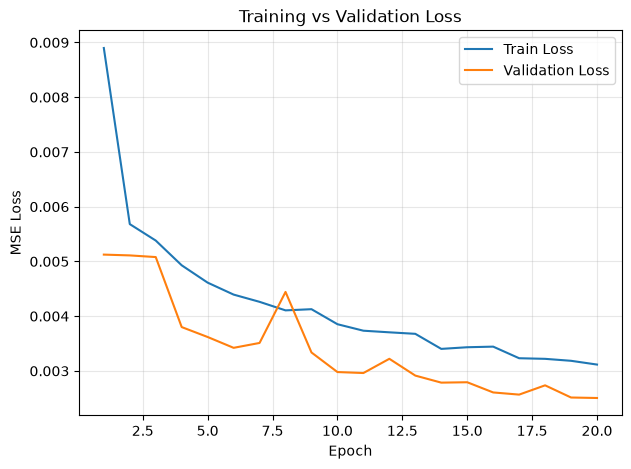

In [10]:
# ---- Plot training/validation loss curves ----
if len(history["train_loss"]) > 0:
    plt.figure(figsize=(7, 5))
    epochs_range = range(1, len(history["train_loss"]) + 1)
    plt.plot(epochs_range, history["train_loss"], label="Train Loss")
    plt.plot(epochs_range, history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("No training history to plot yet.")


**Reading the curves:**
- If **both** curves decrease and roughly track each other → the model is learning a useful,
  generalizing compression of Mars terrain.
- If train loss keeps dropping but val loss **plateaus or rises** → overfitting: the model is
  starting to memorize training-set-specific noise rather than the general terrain distribution.
  Consider more data, stronger regularization, or a smaller latent_dim.
- If **both** curves stay high and flat → underfitting: the model lacks capacity, training ran too
  few epochs, or the learning rate is poorly tuned. Consider more encoder/decoder capacity
  (this is exactly the kind of evidence that motivates a v2 iteration — see §12).

## 7. Reconstruction Visualization

We qualitatively inspect how well the model preserves terrain texture, edges, craters, dunes,
ridgelines and other visible structure. Note: we can only comment on what is *visually*
preserved in the reconstruction — we are not making geological classification claims about
what any given structure actually is.

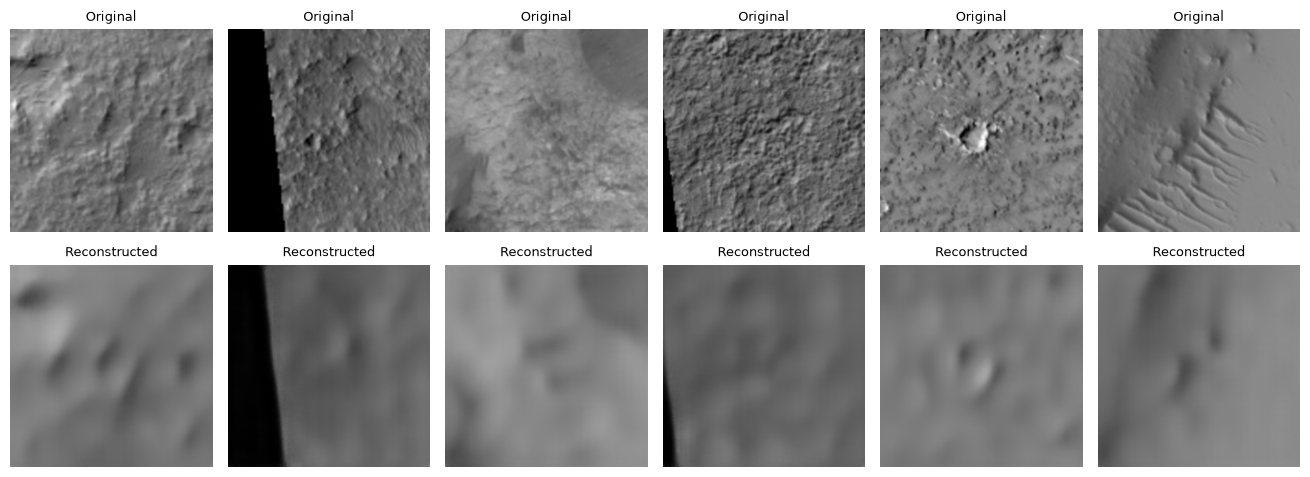

In [11]:
@torch.no_grad()
def show_reconstructions(model, dataset, device, n=6):
    if len(dataset) == 0:
        print("No dataset available to visualize.")
        return

    model.eval()
    n = min(n, len(dataset))
    indices = random.sample(range(len(dataset)), n)

    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 5))
    for col, idx in enumerate(indices):
        img = dataset[idx].unsqueeze(0).to(device)   # [1, 1, 227, 227]
        recon = model(img).cpu().squeeze().numpy()
        orig = img.cpu().squeeze().numpy()

        axes[0, col].imshow(orig, cmap="gray", vmin=0, vmax=1)
        axes[0, col].set_title("Original", fontsize=9)
        axes[0, col].axis("off")

        axes[1, col].imshow(recon, cmap="gray", vmin=0, vmax=1)
        axes[1, col].set_title("Reconstructed", fontsize=9)
        axes[1, col].axis("off")

    plt.tight_layout()
    plt.show()

if len(full_dataset) > 0:
    show_reconstructions(model, full_dataset, device, n=6)
else:
    print("Skipping visualization: no images in DATA_DIR yet.")


## 8. Latent Vector Extraction (hand-off to Phase 2)

We now run every image through the trained encoder to build the full latent matrix, save it to
disk, and print its diagnostics. **This file is the only artifact Phase 2 needs.**

In [ ]:
LATENT_SAVE_PATH = "./latent_vectors.npy"   # change if you prefer a different location

if len(full_dataset) > 0:
    all_latents = extract_all_latents(model, full_dataset, device)

    print(f"Number of images:        {len(full_dataset)}")
    print(f"Latent dimensionality:   {all_latents.shape[1]}")
    print(f"Final latent matrix shape: {tuple(all_latents.shape)}")

    # Fail loudly if shape isn't exactly [num_images, latent_dim]
    assert all_latents.dim() == 2, "Latent matrix must be 2D [num_images, latent_dim]!"
    assert all_latents.shape[0] == len(full_dataset), "Row count must equal number of images!"
    assert all_latents.shape[1] == LATENT_DIM, "Column count must equal latent_dim!"

    np.save(LATENT_SAVE_PATH, all_latents.numpy())
    # Alternative: torch.save(all_latents, "./latent_vectors.pt")
    print(f"\nSaved latent vectors to: {LATENT_SAVE_PATH}")
else:
    print("Skipping latent extraction: no images in DATA_DIR yet.")


**Hand-off point (Phase 2, not implemented here):**

```python
# --- Phase 2 preview only — do not run yet ---
# from sklearn.ensemble import IsolationForest
# latents = np.load("./latent_vectors.npy")   # shape [num_images, latent_dim]
# iso_forest = IsolationForest(contamination="auto", random_state=SEED)
# iso_forest.fit(latents)
# novelty_scores = iso_forest.decision_function(latents)
```

The `latent_vectors.npy` file produced above is exactly what would be loaded here.

## 9. Model Diagnostics Summary

A single cell that re-runs every required sanity check, so you can confirm the implementation
end-to-end at a glance.

In [ ]:
print("=" * 60)
print("MODEL DIAGNOSTICS")
print("=" * 60)

dummy = torch.randn(2, 1, IMG_SIZE, IMG_SIZE).to(device)
z_check = model.encode(dummy)
recon_check = model.decode(z_check)

print(f"[Input shape check]          {tuple(dummy.shape)} == (2, 1, 227, 227) : "
      f"{tuple(dummy.shape) == (2, 1, 227, 227)}")
print(f"[Latent shape check]         {tuple(z_check.shape)} == (2, {LATENT_DIM}) : "
      f"{tuple(z_check.shape) == (2, LATENT_DIM)}")
print(f"[Reconstruction shape check] {tuple(recon_check.shape)} == (2, 1, 227, 227) : "
      f"{tuple(recon_check.shape) == (2, 1, 227, 227)}")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[Parameter count]            total={total_params:,}  trainable={trainable_params:,}")

if len(history['val_loss']) > 0:
    print(f"[Final validation loss]      {history['val_loss'][-1]:.6f}")
else:
    print(f"[Final validation loss]      not available (training was skipped — no data found)")

print("=" * 60)


## 10. Experimenting with `latent_dim`

`latent_dim` is a constructor argument (`ConvAutoencoder(latent_dim=...)`), so comparing
128 / 256 / 512 is a matter of re-instantiating the model and re-running training — nothing else
in the notebook needs to change. We don't auto-train all three here (that's a significant compute
cost across ~10,000 images and is left to you to run deliberately), but here's the pattern:

```python
results = {}
for ld in [128, 256, 512]:
    m = ConvAutoencoder(latent_dim=ld).to(device)
    hist = train_autoencoder(m, train_loader, val_loader, device, num_epochs=20)
    results[ld] = {"model": m, "history": hist}
    # then: show_reconstructions(m, full_dataset, device)
    #       latents = extract_all_latents(m, full_dataset, device)
```

**How to actually choose the final `latent_dim` (do not use validation loss alone):**
- **Reconstruction quality** — visually, via §7, does the smaller latent_dim noticeably blur out
  small craters/ridgelines that the larger one preserves?
- **Validation loss** — a necessary but not sufficient signal; lower isn't automatically better if
  it comes from just memorizing more per-image detail.
- **Preservation of fine structure** — does the reconstruction keep high-frequency terrain detail
  or does it look "smoothed"? This is where Phase 1.2's loss redesign (MSE+SSIM) matters too.
- **Usefulness for downstream anomaly detection** — ultimately the real test (Phase 2) is whether
  Isolation Forest on the resulting latent space actually separates plausible Genesis Outlier
  candidates from normal terrain. A latent space that reconstructs beautifully but where all
  points look identical to Isolation Forest is not actually useful here.

## 11. Architecture Iteration Plan (v1 → v2 → v3)

Phase 4 of the competition asks for an engineering changelog with at least three iterations. The
architecture above is designed to be **v1** — a deliberately straightforward baseline. Below is a
*plan*, not fabricated results, for how v2/v3 would evolve depending on what v1's actual training
run shows.

### V1 — Baseline (this notebook)
A 5-stage strided-conv encoder / mirrored ConvTranspose2d decoder, BatchNorm + LeakyReLU,
`latent_dim=256`, plain MSE loss. Purpose: establish a correct, working baseline and confirm the
pipeline (data → latent → Phase 2 hand-off) end-to-end.

### V2 — Candidate improvement (conditional on V1's actual results)
- **Symptom** *(to be confirmed from real V1 output, not assumed)*: reconstructions in §7 look
  visibly blurred, losing small craters or thin ridgelines; validation loss plateaus early.
- **Diagnosis**: likely insufficient encoder capacity, or the bottleneck is too aggressive for the
  amount of fine detail present in HiRISE crops.
- **Fix**: add an extra conv block before the bottleneck (deeper encoder) and/or increase
  `base_channels`, and/or compare `latent_dim=512` (per §10) before assuming architecture is the
  bottleneck rather than latent size alone.

### V3 — Further refinement (conditional on V2's actual results)
- **Symptom** *(hypothetical, contingent on V2 results)*: V2 improves fine detail but training
  becomes unstable or overfits (train/val loss diverge per §6's curve-reading guide).
- **Diagnosis**: added capacity increased overfitting risk, or BatchNorm statistics are unstable
  at the deeper/larger configuration.
- **Fix**: add light regularization (e.g. dropout in the bottleneck FC layers), and/or revisit
  Phase 1.2's loss function (MSE+SSIM) to give the network a training signal that better preserves
  structure without simply increasing raw capacity.

**Important:** none of the "symptoms" above are claimed as observed facts from this notebook run —
they are the *kind* of evidence that would justify each step, to be filled in with your actual
`history["val_loss"]` numbers and reconstructions once you run this on the real dataset.

## 12. Phase 1.1 Requirements Checklist

| Requirement | Where it's satisfied |
|---|---|
| Built from scratch, no pretrained weights/backbones/transfer learning | `ConvAutoencoder` (§4) — every layer is randomly initialized `nn.Conv2d`/`nn.ConvTranspose2d`/`nn.Linear`, no `torchvision.models` or pretrained checkpoint loaded anywhere |
| Standard DL framework (PyTorch) | Used throughout |
| CAE (not VAE) with justification | §0 (title cell) and §3.2 |
| Architecture designed specifically for 227×227 grayscale | §3.1 shape derivation, `in_channels=1`, all math verified for `IMG_SIZE=227` |
| Fixed-length 1D latent vector | `model.encode(x)` → `[batch, latent_dim]`, asserted in §4.1 and §9 |
| Configurable latent_dim (128/256/512) | `ConvAutoencoder(latent_dim=...)` constructor arg, discussed in §10 |
| Encoder/decoder shape-compatible, no assumed halving | §3.1 explicit `conv_out_size`/`deconv_out_size` derivation + runtime assertions |
| Shape printed at every stage | `verbose=True` in `encode()`/`decode()`, used in §4.1 |
| Architecture justification (conv, downsampling, channels, bottleneck, latent 1D, latent_dim tradeoff) | §3.2 |
| `ConvAutoencoder` class with encoder/bottleneck/decoder, `encode()`/`decode()`/`forward()` | §4 |
| Function to extract latents for entire dataset | `extract_all_latents()` (§4), used in §8 |
| Reconstruction loss (MSE), structured for future MSE+SSIM extension | `reconstruction_loss()` (§5) |
| Full training loop (optimizer, train/val loss, backprop, `.train()`/`.eval()`/`no_grad()`) | §6 |
| Loss curve plots + overfitting/underfitting explanation | §6 |
| Reconstruction visualization (original vs reconstructed) | §7 |
| Latent extraction for full dataset, shape `[N, latent_dim]`, saved to disk | §8 |
| Model diagnostics (shapes, param counts, loss) | §9 |
| latent_dim experimentation pattern (not auto-training all 3) | §10 |
| v1/v2/v3 iteration plan with symptom → diagnosis → fix | §11 |
| Layer-by-layer table + text architecture diagram | §3.2 (bottom), §4.2 |
| No Phase 2 (Isolation Forest) or Phase 3 (heatmaps) implemented | Only a commented preview shown in §8; nothing executed |
| Data loading with configurable path, no labels, explanation of why | §2 |

### Summary — how the pieces fit together
The **encoder** (§4) progressively compresses a 227×227 grayscale image through 5 strided conv
blocks into a 512×7×7 feature map, then flattens and projects it to a `latent_dim`-length vector —
this is the compact "fingerprint" of the image. The **decoder** mirrors this exactly in reverse,
using learned transposed convolutions (with `output_padding` correcting the two stages where 227's
odd size caused a rounding truncation) to reconstruct the original 227×227 image from that vector.
The **bottleneck** (the `Linear` layers at the middle) is what forces the network to learn a
compressed, generalizable representation of *normal* Martian terrain rather than memorizing pixels.
Once trained, `extract_all_latents()` builds a `[num_images, latent_dim]` matrix from every image
in the dataset and saves it — that matrix is exactly what Phase 2's Isolation Forest will consume
to compute novelty scores, without this notebook needing to know anything about Isolation Forest
itself.